# Congestion Classification

Train a Random Forest classifier to predict traffic state from sensor features.

In [1]:
import sys
sys.path.append("../src")
from preprocess import load_data, engineer_features, encode_labels, get_feature_columns
from classify_congestion import train_model, get_feature_importance

df = load_data()
df = engineer_features(df)
df, state_map = encode_labels(df)
df.head()

,intersection_id,timestamp,hour,day_of_week,vehicle_count,avg_speed_kmh,density,traffic_state,hour_sin,hour_cos,is_rush_hour,is_weekend,rolling_avg_vehicles,traffic_state_encoded
0,1,2026-01-01 00:00:00,0,Thursday,17,50.7,0.28,Free Flow,0.000000,1.000000,0,0,17.000000,0
1,1,2026-01-01 00:15:00,0,Thursday,8,56.3,0.13,Free Flow,0.000000,1.000000,0,0,12.500000,0
2,1,2026-01-01 00:30:00,0,Thursday,6,56.0,0.10,Free Flow,0.000000,1.000000,0,0,10.333333,0
3,1,2026-01-01 00:45:00,0,Thursday,13,54.2,0.22,Free Flow,0.000000,1.000000,0,0,11.000000,0
4,1,2026-01-01 01:00:00,1,Thursday,23,57.0,0.38,Free Flow,0.258819,0.965926,0,0,12.500000,0


## Train the model

In [2]:
feature_cols = get_feature_columns()
model, acc = train_model(df, feature_cols)
print(f"Test accuracy: {acc:.2%}")

Model accuracy: 99.85%

Classification report:
              precision    recall  f1-score   support

   Free Flow       1.00      1.00      1.00       374
    Moderate       1.00      1.00      1.00       183
   Congested       0.99      1.00      0.99        67
    Critical       1.00      0.98      0.99        48

    accuracy                           1.00       672
   macro avg       1.00      0.99      1.00       672
weighted avg       1.00      1.00      1.00       672

Confusion matrix:
[[374   0   0   0]
 [  0 183   0   0]
 [  0   0  67   0]
 [  0   0   1  47]]
Test accuracy: 99.85%


## Feature importance

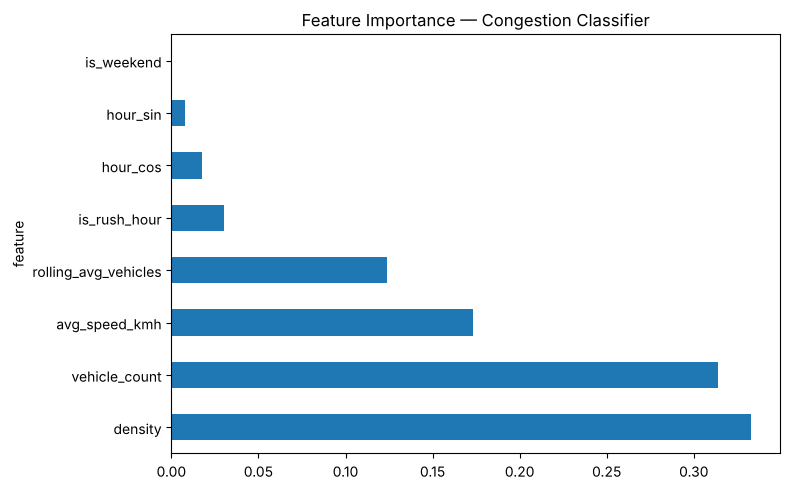

In [3]:
importance = get_feature_importance(model, feature_cols)
importance.plot(kind="barh", x="feature", y="importance", legend=False, figsize=(8,5))
import matplotlib.pyplot as plt
plt.title("Feature Importance — Congestion Classifier")
plt.tight_layout()
plt.show()